# 05 · Findings and recommendation

**Project question:** Do Los Angeles neighborhoods with many limited-English households get slower or less city service than comparable neighborhoods, even after accounting for income and the type of request?

This notebook pulls the results of notebooks 3 and 4 into one place: the headline numbers (computed from the saved results tables, not typed in), a chart of how robust they are, the recommendation, and the extracts used by the Power BI dashboard.

In [1]:
import re, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50, "display.width", 150)
PROC, RAW = "../data/processed", "../data/raw"
speed_sens = pd.read_csv(f"{PROC}/results_speed_sensitivity.csv")
speed_days = pd.read_csv(f"{PROC}/results_speed_days.csv", index_col=0)
km = pd.read_csv(f"{PROC}/results_speed_km.csv")
gap_main = pd.read_csv(f"{PROC}/results_gap_main.csv")
gap_sens = pd.read_csv(f"{PROC}/results_gap_sensitivity.csv")
gap_q = pd.read_csv(f"{PROC}/results_gap_quintiles.csv", index_col=0)
tr = pd.read_csv(f"{PROC}/tract_reporting_gap.csv", dtype={"geoid": str})

## 1. The headline numbers

In [2]:
m = speed_sens.set_index("variant").loc["Main"]
lo, hi = [float(x) for x in re.findall(r"[-+]?\d+\.?\d*", m.pct_ci)]
g = gap_main.set_index("outcome")
print(f"SPEED  : +10 pts limited-English share -> {m.pct_change_time_per_10pts:+.1f}% time-to-close (95% CI {lo:+.1f}% to {hi:+.1f}%)")
print(f"         = about {speed_days.effect_days_per_10pts.mean():+.2f} days at a typical 2-day wait; 30-day closure {m.pp_closed30_per_10pts:+.2f} pp")
a = g.loc["All resident requests"]
print(f"FILING : +10 pts limited-English share -> {a.pct:+.1f}% requests per household (95% CI {a.ci_low:+.1f}% to {a.ci_high:+.1f}%)")
q1, q5 = gap_q.loc[1], gap_q.loc[5]
print(f"         raw rates per household per year: Q1 {q1.resident_per_hh_yr:.2f}, Q5 {q5.resident_per_hh_yr:.2f}")
print(f"TRACTS : {int(((tr.quintile==5) & (tr.obs_exp < tr.obs_exp.quantile(.25))).sum())} top-quintile tracts in the lowest quarter of observed/expected; "
      f"{int(((tr.quintile==5) & (tr.obs_exp < 0.5)).sum())} below 0.5")

SPEED  : +10 pts limited-English share -> -1.2% time-to-close (95% CI -2.4% to +0.1%)
         = about -0.03 days at a typical 2-day wait; 30-day closure +0.02 pp
FILING : +10 pts limited-English share -> +11.4% requests per household (95% CI +7.6% to +15.5%)
         raw rates per household per year: Q1 0.68, Q5 0.85
TRACTS : 46 top-quintile tracts in the lowest quarter of observed/expected; 10 below 0.5


## 2. How robust is it?
Each dot is one version of the analysis (different data cuts or models); the line is the 95% confidence interval. If the dots all sit on the same side of zero, the conclusion doesn't depend on any one choice.

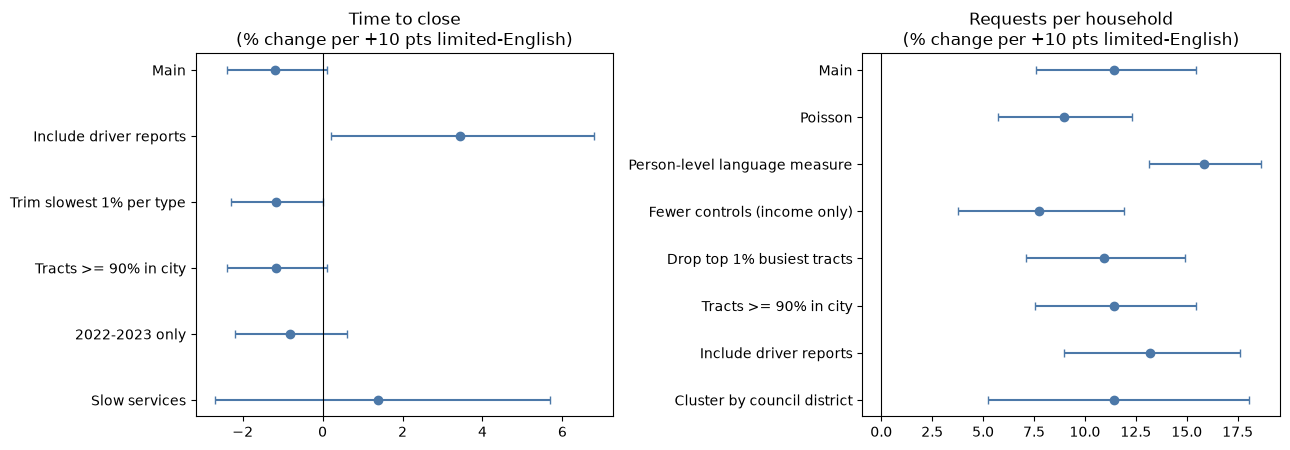

In [3]:
def parse(ci): return [float(x) for x in re.findall(r"[-+]?\d+\.?\d*", ci)]
sp = speed_sens.copy(); sp[["lo","hi"]] = sp.pct_ci.apply(parse).apply(pd.Series)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a_, d, col, lo_, hi_, mid, title in [
    (ax[0], sp, "variant", "lo", "hi", "pct_change_time_per_10pts", "Time to close\n(% change per +10 pts limited-English)"),
    (ax[1], gap_sens, "variant", "ci_low", "ci_high", "pct", "Requests per household\n(% change per +10 pts limited-English)")]:
    y = np.arange(len(d))[::-1]
    a_.errorbar(d[mid], y, xerr=[d[mid]-d[lo_], d[hi_]-d[mid]], fmt="o", color="#4c78a8", capsize=3)
    a_.axvline(0, color="k", lw=.8); a_.set_yticks(y); a_.set_yticklabels(d[col]); a_.set_title(title)
plt.tight_layout(); plt.show()

Reading the chart: on the left, every check clusters around zero (about 1% faster or slower; the "include driver reports" row is the measurement artifact from notebook 3). On the right, every check is clearly above zero.

## 3. Where the tracts are
Among the tracts with the highest share of limited-English households, I flagged those that file far fewer 311 requests than their housing and demographics would predict. A low count could mean fewer problems or fewer reports, which this data can’t separate, so these tracts are candidates for follow-up rather than evidence of under-reporting.

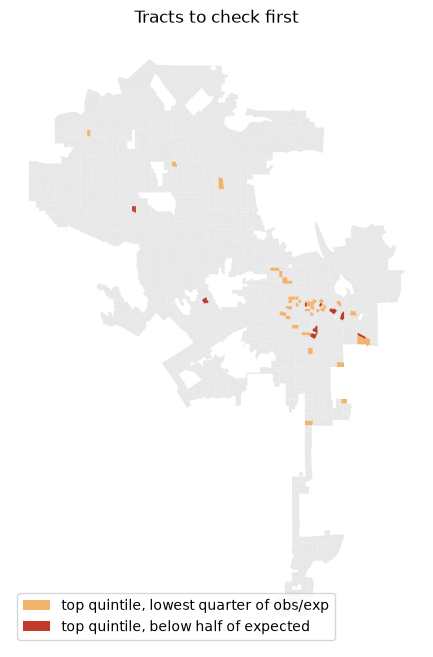

flag
other                              1045
top quintile, lowest quarter         36
top quintile, < 0.5 of expected      10
Name: count, dtype: int64

In [4]:
tracts = gpd.read_file(f"{RAW}/tl_2023_06_tract/tl_2023_06_tract.shp")[["GEOID", "geometry"]]
tracts = tracts.merge(tr, left_on="GEOID", right_on="geoid")
q25 = tr.obs_exp.quantile(.25)
tracts["flag"] = np.select([(tracts.quintile==5) & (tracts.obs_exp < 0.5), (tracts.quintile==5) & (tracts.obs_exp < q25)],
                           ["top quintile, < 0.5 of expected", "top quintile, lowest quarter"], "other")
fig, ax = plt.subplots(figsize=(8, 8))
tracts[tracts.flag=="other"].plot(ax=ax, color="#e8e8e8", linewidth=0)
tracts[tracts.flag=="top quintile, lowest quarter"].plot(ax=ax, color="#f2b36d", linewidth=0, label="top quintile, lowest quarter of obs/exp")
tracts[tracts.flag=="top quintile, < 0.5 of expected"].plot(ax=ax, color="#c0392b", linewidth=0, label="top quintile, below half of expected")
ax.legend(loc="lower left"); ax.axis("off"); ax.set_title("Tracts to check first"); plt.show()
tracts.flag.value_counts()

## 4. Recommendation

**Bottom line.** In this data, language is not what separates the neighborhoods that get slower or less city service. Limited-English tracts do not wait longer for the services we can compare, and they do not file fewer requests per household. A city or nonprofit looking for the cause of unequal service should look elsewhere first.

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Don't make language access the first fix for slow closure of bulky-item, dumping, graffiti, appliance and e-waste requests.** | Time-to-close differs by about 1% per 10 points of limited-English share, in the faster direction; 30-day closure is unchanged |
| 2 | **Look at the slow services regardless of neighborhood.** Encampment requests take a median of about 27–45 days and streetlights about 80–130 days, with a quarter to a third still open. | Notebook 1 and 3 descriptives. This is a department capacity issue, not a language one |
| 3 | **Keep investing in the channels limited-English tracts already use, such as mobile app.** The app's share of requests rises from 31% to 42% with limited-English share while phone use falls from 49% to 39%. | Notebook 4, section 5 (descriptive; worth testing, not proven) |
| 4 | **Spot-check the 10 to 46 flagged tracts** with a field visit, a short survey, or a community partner, to see whether low filing reflects fewer problems or barriers to reporting. | Notebook 4 observed/expected list. The only way to separate "fewer problems" from "fewer reports" is to measure conditions directly |
| 5 | **Collect better data:** record the language of each 311 contact, flag administrative closures, and log the true completion date. | Limits found in notebooks 1 and 3 (driver tickets that close in minutes, graffiti medians near zero) |

### Limits
- Tract averages say nothing about individual households or people.
- A null result is not proof of fair treatment. Request types, building age, and department workloads can explain differences in either direction, and we have no direct measure of neighborhood conditions.
- `ClosedDate` is when the ticket was closed, not necessarily when the work was finished.
- Covers the City of LA, 2022–2024 requests, 2019–2023 ACS estimates. COVID years were left out on purpose, so findings describe the post-pandemic period.
- Neighboring tracts are not independent; the clustered intervals are rough.
- The same method could be applied to any city that publishes 311-style data, or to an organization's own service data (for example, appointment no-shows or complaint response times).

## 5. Export the extracts for Power BI 

In [5]:
import os
os.makedirs(f"{PROC}/powerbi", exist_ok=True)
cols = ["geoid","households","lep_share","lep_person","quintile","median_income","renter_share","old_housing","density",
        "n_resident","n_problem","n_service","expected","obs_exp","flag"]
out = tracts[cols + ["geometry"]].copy()
out["resident_per_hh_yr"] = out.n_resident / out.households / 3
out["problem_per_hh_yr"] = out.n_problem / out.households / 3
out = out.to_crs(4326)
# Full-detail GeoJSON (Azure Maps reference layer) and a lighter copy for the Shape Map visual (convert to TopoJSON in mapshaper.org)
out.to_file(f"{PROC}/powerbi/tracts.geojson", driver="GeoJSON")
out.assign(geometry=out.geometry.simplify(0.0005, preserve_topology=True)).to_file(f"{PROC}/powerbi/tracts_simplified.geojson", driver="GeoJSON")
# In Power BI, set geoid to Text in Power Query, otherwise the leading 0 is dropped and joins to the boundaries fail
out.drop(columns="geometry").to_csv(f"{PROC}/powerbi/tracts.csv", index=False)
km.to_csv(f"{PROC}/powerbi/speed_by_quintile.csv", index=False)
gap_q.reset_index().to_csv(f"{PROC}/powerbi/rates_by_quintile.csv", index=False)
print(sorted(os.listdir(f"{PROC}/powerbi")))

['rates_by_quintile.csv', 'speed_by_quintile.csv', 'tracts.csv', 'tracts.geojson', 'tracts_simplified.geojson']
